# Setup

In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

In [2]:
df_base = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [3]:
df_base.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [4]:
feats_categ = df_base.select_dtypes(include='str').columns.tolist()
feats_numer = df_base.select_dtypes(exclude='str').columns.tolist()
feats_numer.remove('converted')

In [5]:
print(df_base[feats_categ].isnull().sum())
print('- '*10)
print(df_base[feats_numer].isnull().sum())

lead_source          148
industry             240
employment_status    194
location             208
dtype: int64
- - - - - - - - - - 
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
dtype: int64


In [6]:
df_base[feats_categ] = df_base[feats_categ].fillna('NA')
df_base[feats_numer] = df_base[feats_numer].fillna(0)

In [7]:
print(df_base[feats_categ].isnull().sum())
print('- '*10)
print(df_base[feats_numer].isnull().sum())

lead_source          0
industry             0
employment_status    0
location             0
dtype: int64
- - - - - - - - - - 
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df_base, test_size=0.20, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
len(df_train), len(df_val), len(df_test)

for name in tqdm(['train', 'val', 'test']):
    df = globals()[f'df_{name}'].reset_index(drop=True)
    globals()[f'df_{name}'] = df
    globals()[f'y_{name}'] = df.converted.values

100%|██████████| 3/3 [00:00<?, ?it/s]


# Question 1

In [9]:
print("Categorical Features")
print("- " * 10)

for f in feats_categ:
    dv_f = DictVectorizer(sparse=False)
    Xtr = dv_f.fit_transform(df_train[[f]].to_dict(orient='records'))
    Xva = dv_f.transform(df_val[[f]].to_dict(orient='records'))

    model = LogisticRegression(max_iter=1000)
    model.fit(Xtr, y_train)
    y_pred = model.predict_proba(Xva)[:, 1]
    print(f, round(roc_auc_score(y_val, y_pred), 3))

Categorical Features
- - - - - - - - - - 
lead_source 0.646
industry 0.523
employment_status 0.605
location 0.516


In [10]:
print("Numeric Features")
print("- " * 10)
for f in feats_numer:
    model = LogisticRegression(max_iter=len(y_train))
    model.fit(df_train[[f]], y_train)
    y_pred = model.predict_proba(df_val[[f]])[:, 1]
    print(f, round(roc_auc_score(y_val, y_pred), 3))

Numeric Features
- - - - - - - - - - 
annual_income 0.613
number_of_courses_viewed 0.714
interaction_count 0.763
lead_score 0.783


# Question 2

In [11]:
dv = DictVectorizer(sparse=False)
for name in tqdm(['train', 'val', 'test']):
    df = globals()[f'df_{name}']
    d = df[feats_categ + feats_numer].to_dict(orient='records')
    globals()[f'X_{name}'] = dv.fit_transform(d)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

round(roc_auc_score(y_val, y_pred), 3)

100%|██████████| 3/3 [00:00<00:00, 27.31it/s]


0.732

# Question 3

100%|██████████| 101/101 [00:00<00:00, 170.51it/s]


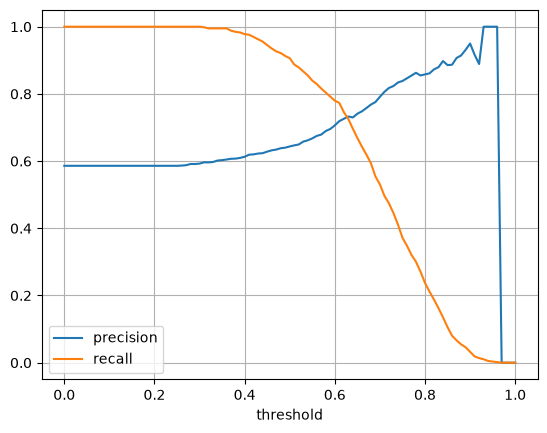

In [12]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0, 1.01, 0.01)
precisions, recalls = [], []

for t in tqdm(thresholds):
    y_hat = (y_pred >= t).astype(int)
    precisions.append(precision_score(y_val, y_hat, zero_division=0))
    recalls.append(recall_score(y_val, y_hat, zero_division=0))

import matplotlib.pyplot as plt

plt.plot(thresholds, precisions, label='precision')
plt.plot(thresholds, recalls, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.grid(True)
plt.show()

# Question 4

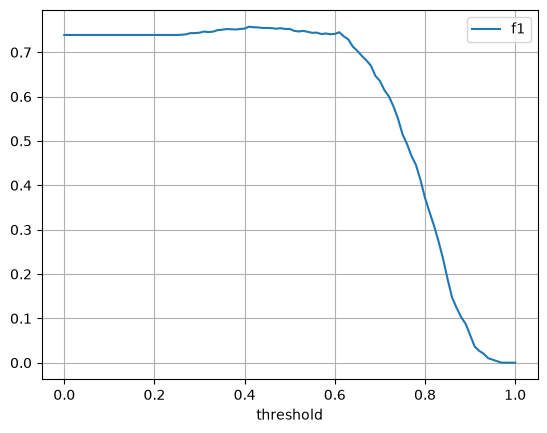

In [13]:
from sklearn.metrics import f1_score

thresholds = np.arange(0, 1.01, 0.01)
f1s = []

for t in thresholds:
    y_hat = (y_pred >= t).astype(int)
    f1s.append(f1_score(y_val, y_hat, zero_division=0))

plt.plot(thresholds, f1s, label='f1')
plt.xlabel('threshold')
plt.legend()
plt.grid(True)
plt.show()

# Question 5

In [14]:
n_splits = 5
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

for c in [0.000001, 0.001, 1]:
    
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
    
        X_train = dv.fit_transform(df_train[feats_categ + feats_numer].to_dict(orient='records'))
        X_val = dv.transform(df_val[feats_categ + feats_numer].to_dict(orient='records'))
    
        model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        model.fit(X_train, y_train)
        y_pred = model.predict_proba(X_val)[:, 1]
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    
    print(f"c-{c:.6f}: {round(np.mean(scores), 3)}")

c-0.000001: 0.617
c-0.001000: 0.749
c-1.000000: 0.732
